
Correlazione tra GameWeight e ComWeight:
 0.9972676961471039

Correlazione tra MfgPlaytime e ComMaxPlaytime:
 0.9999999999999998

FINE: trasformazione applicata

  - Trasformazione Logaritmica applicata a: ['MinPlayers', 'MaxPlayers', 'NumOwned', 'NumWant', 'NumWish', 'NumWeightVotes', 'MfgPlaytime', 'ComMinPlaytime', 'NumUserRatings', 'NumAlternates', 'NumExpansions', 'NumImplementations']

  - Trasformazione Radice Cubica applicata a: ['YearPublished']

Vi sono 1079 possibili outlier

Percentuale di outlier:
 5.00%

Varianza totale spiegata dalle 3 componenti: 58.05%


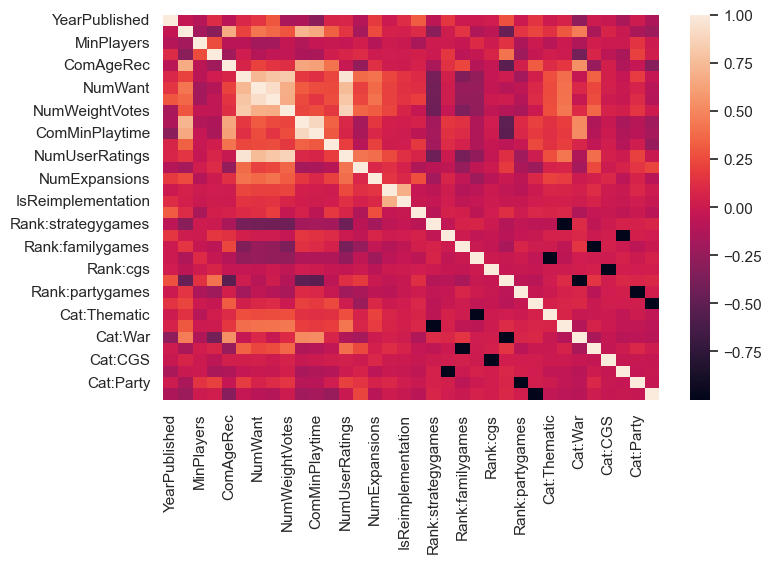

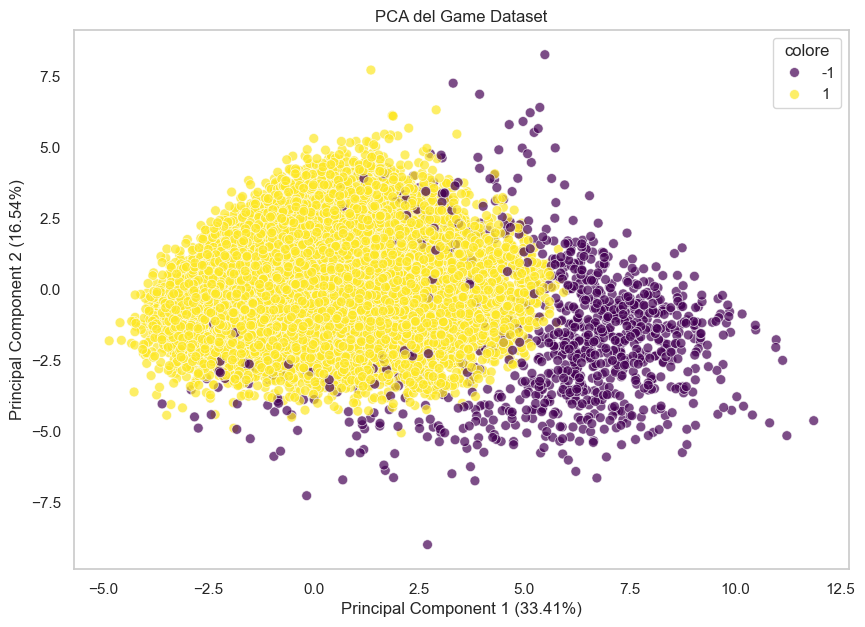

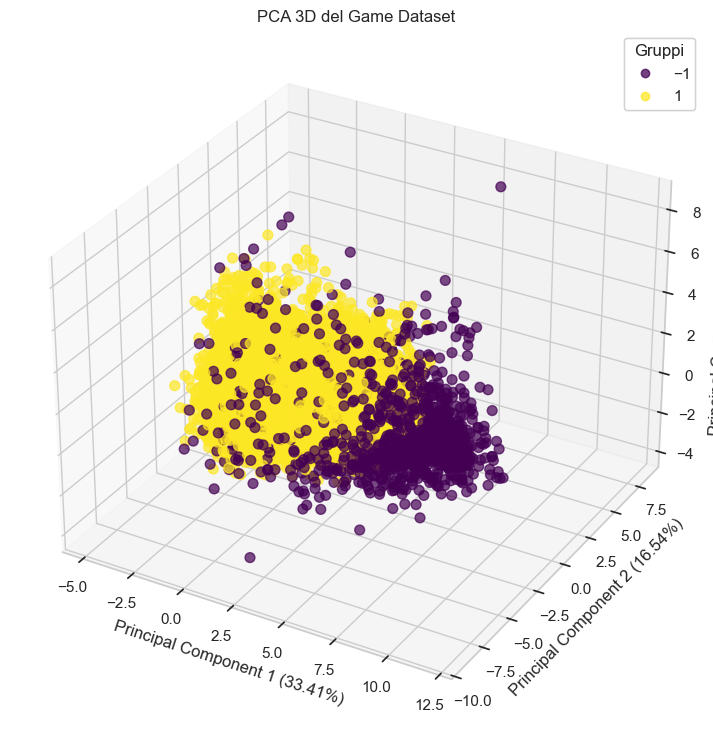

In [1]:
# LIBRERIE
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.impute import KNNImputer
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Stile generale per i grafici
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)


# CARICAMENTO DATAFRAME
df = pd.read_csv("/Users/ale/Documents/primo anno/dm1_25_26_dataset/df/DM1_game_dataset.csv")


# -----------------------------------------------
# -----------------------------------------------
# ANALISI ESPLORATIVA

'''
# Describe generale
df_describe = df.describe(include="all")


# Funzione di dispersione
def dispersione(Disp):
    return pd.Series({
        "Varianza": Disp.var(),
        "Deviazione std": Disp.std(),
        "Range": Disp.max() - Disp.min(),
        "IQR": Disp.quantile(0.75) - Disp.quantile(0.25),
        "Coeff. Variazione": (Disp.std() / Disp.mean())
    })


#GameWeight
print(f"STATISTICHE DESCRITTIVE:\n{df['GameWeight'].describe(include='all')}")
print(f"MODA:\n{df['GameWeight'].mode()}")
print(f"STATISTICHE DI DISPERSIONE:\n{dispersione(df["GameWeight"])}")
oppa1= [df['GameWeight'].describe(include='all'), df['GameWeight'].mode(), dispersione(df["GameWeight"])]
df_gameweight_stats = pd.concat(oppa1)

sns.histplot(df, x="GameWeight", color="red", alpha=1)
plt.title("Istogramma GameWeight")
plt.xlabel("GameWeight")
plt.ylabel("Numerosità")
plt.show()

sns.kdeplot(df, x="GameWeight", color="red", alpha=1)
plt.title("Densità GameWeight")
plt.xlabel("GameWeight")
plt.ylabel("Densità")
plt.show()


# MfgPlaytime
df_mfgplaytime = df[df["MfgPlaytime"] > 0]
print(
    f"STATISTICHE DESCRITTIVE:\n{df_mfgplaytime['MfgPlaytime'].describe(include='all')}")
print(f"MODA:\n{df_mfgplaytime['MfgPlaytime'].mode()}")
print(
    f"STATISTICHE DI DISPERSIONE:\n{dispersione(df_mfgplaytime["MfgPlaytime"])}")
oppa_mfgplaytime = [df_mfgplaytime['MfgPlaytime'].describe(
    include='all'), df_mfgplaytime['MfgPlaytime'].mode(), dispersione(df_mfgplaytime["MfgPlaytime"])]
df_mfgplaytime_stats = pd.concat(oppa_mfgplaytime)
count_mfgplaytime = df_mfgplaytime["MfgPlaytime"].value_counts()
print(count_mfgplaytime)
# ho rimosso i valori 0
# ci sono alcuni (pochi) giochi con un tempo di completamento molto alto (qualcosa come 48h+)


# ComMinPlaytime
df_comminplaytime = df[df["ComMinPlaytime"] > 0]
print(
    f"STATISTICHE DESCRITTIVE:\n{df_comminplaytime['ComMinPlaytime'].describe(include='all')}")
print(f"MODA:\n{df_comminplaytime['ComMinPlaytime'].mode()}")
print(
    f"STATISTICHE DI DISPERSIONE:\n{dispersione(df_comminplaytime["ComMinPlaytime"])}")
oppa_comminplaytime = [df_comminplaytime['ComMinPlaytime'].describe(
    include='all'), df_comminplaytime['ComMinPlaytime'].mode(), dispersione(df_comminplaytime["ComMinPlaytime"])]
df_comminplaytime_stats = pd.concat(oppa_comminplaytime)
count_comminplaytime = df_comminplaytime["ComMinPlaytime"].value_counts()
print(count_comminplaytime)
# secondo la comunity ci vuole in generale meno tempo per finire i giochi
# ho rimosso i valori 0
# ci sono alcuni (pochi) giochi con un tempo di completamento molto alto (qualcosa come 48h+)


# ComMaxPlaytime
df_commaxplaytime = df[df["ComMaxPlaytime"] > 0]
print(
    f"STATISTICHE DESCRITTIVE:\n{df_commaxplaytime['ComMaxPlaytime'].describe(include='all')}")
print(f"MODA:\n{df_commaxplaytime['ComMaxPlaytime'].mode()}")
print(
    f"STATISTICHE DI DISPERSIONE:\n{dispersione(df_commaxplaytime["ComMaxPlaytime"])}")
oppa_commaxplaytime = [df_commaxplaytime['ComMaxPlaytime'].describe(
    include='all'), df_commaxplaytime['ComMaxPlaytime'].mode(), dispersione(df_commaxplaytime["ComMaxPlaytime"])]
df_commaxplaytime_stats = pd.concat(oppa_commaxplaytime)
count_commaxplaytime = df_commaxplaytime["ComMaxPlaytime"].value_counts()
print(count_commaxplaytime)

gne = df[["ComMaxPlaytime", "MfgPlaytime"]]
print(
    f"Sono le stesse colonne?:\n {(df["ComMaxPlaytime"] == df["MfgPlaytime"]).all()}")
# ComMaxPlaytime e MfgPlaytime SONO IDENTICHE? HO SBAGLIATO QUALCOSA?


# MfgAgeRec
df_mfgagerec = df[df["MfgAgeRec"] > 0]
print(
    f"STATISTICHE DESCRITTIVE:\n{df_mfgagerec['MfgAgeRec'].describe(include='all')}")
print(f"MODA:\n{df_mfgagerec['MfgAgeRec'].mode()}")
print(f"STATISTICHE DI DISPERSIONE:\n{dispersione(df_mfgagerec["MfgAgeRec"])}")
oppa_mfgagerec = [df_mfgagerec['MfgAgeRec'].describe(
    include='all'), df_mfgagerec['MfgAgeRec'].mode(), dispersione(df_mfgagerec["MfgAgeRec"])]
df_mfgagerec_stats = pd.concat(oppa_mfgagerec)
count_mfgagerec = df_mfgagerec["MfgAgeRec"].value_counts()
print(count_mfgagerec)

# valori (pochi) =0 esclusi, tendenza centrale con 3 picchi intorno alla media/mediana

# LanguageEase
# https://boardgamegeek.com/wiki/page/language-independent
df_languageease = df[df["LanguageEase"] > 0]
print(
    f"STATISTICHE DESCRITTIVE:\n{df_languageease['LanguageEase'].describe(include='all')}")
print(f"MODA:\n{df_languageease['LanguageEase'].mode()}")
print(
    f"STATISTICHE DI DISPERSIONE:\n{dispersione(df_languageease["LanguageEase"])}")
oppa_languageease = [df_languageease['LanguageEase'].describe(
    include='all'), df_languageease['LanguageEase'].mode(), dispersione(df_languageease["LanguageEase"])]
df_languageease_stats = pd.concat(oppa_languageease)
count_languageease = df_languageease["LanguageEase"].value_counts()
print(count_languageease)
# boh, i valori mi sembrano tutti sballati
# dopo qualche ricerca: COMPLETAMENTE SBALLATO

# NumWeightVotes
df_numweightvotes = df[df["NumWeightVotes"] > 0]
print(
    f"STATISTICHE DESCRITTIVE:\n{df_numweightvotes['NumWeightVotes'].describe(include='all')}")
print(f"MODA:\n{df_numweightvotes['NumWeightVotes'].mode()}")
print(
    f"STATISTICHE DI DISPERSIONE:\n{dispersione(df_numweightvotes["NumWeightVotes"])}")
oppa_numweightvotes = [df_numweightvotes['NumWeightVotes'].describe(
    include='all'), df_numweightvotes['NumWeightVotes'].mode(), dispersione(df_numweightvotes["NumWeightVotes"])]
df_numweightvotes_stats = pd.concat(oppa_numweightvotes)
count_numweightvotes = df_numweightvotes["NumWeightVotes"].value_counts()
print(count_numweightvotes)
# NUmero di persone che hanno votato per la complessità
# Tutto normale, qualche outlier in eccesso (Carcassone es.)


# Kickstarted
print(
    f"Variabile kickstarter binaria, conta:\n{df["Kickstarted"].value_counts()}")
# 3362 giochi sono stati finanziati dai fan


# CATEGORIE e RANKING
categorie = ["Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
             "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens"]
df["multi_categoria"] = df[categorie].sum(axis=1) > 1
multi_categorie = df[df[categorie].sum(axis=1) > 1]
# 1574 giochi fanno parte di più di una categoria

pairs = list(itertools.combinations(categorie, 2))
pair_counts = {}
for a, b in pairs:
    pair_counts[(a, b)] = ((multi_categorie[a] == 1)
                           & (multi_categorie[b] == 1)).sum()

pair_df = pd.DataFrame(pair_counts.items(), columns=["Pair", "Count"])
# in caso te ne scordi, il >0 vuol dire che teniamo solo le coppie esistenti
pair_df = pair_df[pair_df["Count"] > 0]


#cambio i valori inutili nel ranking con null
colonne_rank = [
    "Rank:strategygames",
    "Rank:abstracts",
    "Rank:familygames",
    "Rank:thematic",
    "Rank:cgs",
    "Rank:wargames",
    "Rank:partygames",
    "Rank:childrensgames"
]
df[colonne_rank] = df[colonne_rank].replace(21926, np.nan)
'''


# -----------------------------------------------
# -----------------------------------------------
# DROPPING VARIABILI & CAMBIO


# Dropping explanation
print(
    f"\nCorrelazione tra GameWeight e ComWeight:\n {df["GameWeight"].corr(df["ComWeight"])}")
print(
    f"\nCorrelazione tra MfgPlaytime e ComMaxPlaytime:\n {df["MfgPlaytime"].corr(df["ComMaxPlaytime"])}")


# Dropping worthless variables
df = df.drop(["ComWeight", "LanguageEase", "BestPlayers", "GoodPlayers",
              "ComMaxPlaytime", "NumComments", "ImagePath"], axis=1)


# Cambio di RATING
'''df["Rating"] = df["Rating"].replace("Low", "1")
df["Rating"] = df["Rating"].replace("Medium", "2")
df["Rating"] = df["Rating"].replace("High", "3")  '''


# Parentesi Quadre come null
'''df = df.replace("[]", np.nan)'''


# -----------------------------------------------
# -----------------------------------------------
# MISSING VALUES


# Missing Values: Episode I - The Phantom Value

# YearPublished -> missing values si lehano
df = df[df["YearPublished"] != 0]
# Players -> missing values si lehano
df = df[df["MinPlayers"] != 0]
df = df[df["MaxPlayers"] != 0]
# Family -> Rinomino missing values to a category
df["Family"] = df["Family"].fillna("No_Family")
# df["Family"] = df["Family"].replace(np.nan, "No_Family")  #Alternativa alla riga sopra
# Playtime-> Si usa la moda
df["MfgPlaytime"] = df["MfgPlaytime"].replace(0, df["MfgPlaytime"].mode()[0])
df["ComMinPlaytime"] = df["ComMinPlaytime"].replace(
    0, df["ComMinPlaytime"].mode()[0])


# Missing Values: Episode II - Attack of the imputation

# In pratica ho usato due tecniche basilari (Random Forest, Knn)
# e una avanzata (MICE) per generare valori mancanti di GameWeight
# Chiaramente, solo un modello è da utilizzare, se runnati insieme il primo
# sostituisce i valori mancanti, e gli altri non fanno nulla
# GameWeight ha circa 500 missing values (in realtà sono valori 0, ma è lo stesso discorso)


# Random_Forest
df["GameWeight"] = df["GameWeight"].replace(0, np.nan)
df_solo_numeriche = df.select_dtypes(include=["number"])
df_solo_numeriche = df_solo_numeriche.drop([
    "Rank:strategygames",
    "Rank:abstracts",
    "Rank:familygames",
    "Rank:thematic",
    "Rank:cgs",
    "Rank:wargames",
    "Rank:partygames",
    "Rank:childrensgames"
], axis=1)
valori = df_solo_numeriche[df_solo_numeriche["GameWeight"].notna()]
missing = df_solo_numeriche[df_solo_numeriche["GameWeight"].isna()]
X_train = valori.drop(columns=["GameWeight"])
y_train = valori["GameWeight"]
X_missing = missing.drop(columns=["GameWeight"])
modello_RF = RandomForestRegressor(random_state=222)
modello_RF.fit(X_train, y_train)
predizione = modello_RF.predict(X_missing)
df.loc[df["GameWeight"].isna(), "GameWeight"] = predizione


'''# KNN_Imputer
predittori = df_solo_numeriche.drop(columns=["GameWeight"])
# per riorganizzare il dataset
df_knn = pd.concat([df_solo_numeriche["GameWeight"], predittori], axis=1)
# si potrebbe aumentare, ma non ne vedo il motivo
imputer = KNNImputer(n_neighbors=5)
df_imputato = imputer.fit_transform(df_knn)
df_solo_numeriche["GameWeight"] = df_imputato[:, 0]'''


'''# MICE usando linear regression (mi sembra la più opportuna)
imputer = IterativeImputer(random_state=222, max_iter=100)
imputer.fit(df_solo_numeriche)
df_imputato = imputer.transform(df_solo_numeriche)
df["GameWeight"] = df_imputato[:,
                               df_solo_numeriche.columns.get_loc("GameWeight")]
# Sfortunatamente, con MICE escono fuori valori <1, quindi lo scarterei o si cambia qualcosa tra i parametri
df["GameWeight"] = df["GameWeight"].clip(lower=1)
# soluzione: si clippano i valori minori di 1 con 1
# in realtà, si potrebbe usare un MICE Random Forest, ma diventa pesante'''

count_peso = df["GameWeight"].value_counts()


# -----------------------------------------------
# -----------------------------------------------
# TRASFORMAZIONE VARIABILI


numeriche = df.select_dtypes(include=["int64", "float64"]).columns
categoriche = df.select_dtypes(include=["object", "category"]).columns
numeriche = numeriche.drop([
    "BGGId",
    "Rank:strategygames",
    "Rank:abstracts",
    "Rank:familygames",
    "Rank:thematic",
    "Rank:cgs",
    "Rank:wargames",
    "Rank:partygames",
    "Rank:childrensgames",
    "Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family", "Cat:CGS",
    "Cat:Abstract", "Cat:Party", "Cat:Childrens",
    "Kickstarted", "IsReimplementation"
])


# Grafici per ogni quantitativa
'''for col in numeriche:
    sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.show()
'''

# Skewness
valori_skew = df[numeriche].skew()
# print(f"\nSkewness originale:\n{valori_skew}\n")


def trasformatore(dataframe: pd.DataFrame, colonne: list, soglia: float = 1.0) -> pd.DataFrame:

    df_copy = dataframe.copy()
    skew_values = df_copy[colonne].skew()
    colonne_da_trasformare = skew_values[abs(skew_values) > soglia].index

    if colonne_da_trasformare.empty:
        print(f"\nFINE: nessuna colonna con skewness > |{soglia}|.")
        return df_copy

    col_log = []
    col_cbrt = []

    for col in colonne_da_trasformare:

        if df_copy[col].min() < 0:
            df_copy[col] = np.cbrt(df_copy[col])
            col_cbrt.append(col)
        else:
            df_copy[col] = np.log1p(df_copy[col])
            col_log.append(col)

    print("\nFINE: trasformazione applicata")
    if col_log:
        print(f"\n  - Trasformazione Logaritmica applicata a: {col_log}")
    if col_cbrt:
        print(f"\n  - Trasformazione Radice Cubica applicata a: {col_cbrt}")

    return df_copy


df_corretto = trasformatore(df, numeriche.tolist())

  
# -----------------------------------------------
# -----------------------------------------------
# OUTLIERS


iforest = IsolationForest(
    n_estimators=100, contamination=0.05, random_state=222)

numeriche_corretto = df_corretto[numeriche]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(numeriche_corretto)
y_pred_iforest = iforest.fit_predict(X_scaled)

df_corretto["outlier"] = y_pred_iforest

print(f"\nVi sono {np.sum(y_pred_iforest == -1)} possibili outlier")

df_outliers = df_corretto[df_corretto["outlier"] == -1]

print(
    f"\nPercentuale di outlier:\n {len(df_outliers) / len(df_corretto) * 100:.2f}%")


df_capped = df_corretto.copy()
LOWER_LIMIT = 0.05
UPPER_LIMIT = 0.95
#bisogna giocare con questi valori, sono alti ma ci sono anche tanti outliers

for col in numeriche:

    lower_bound = df_capped[col].quantile(LOWER_LIMIT)
    upper_bound = df_capped[col].quantile(UPPER_LIMIT)

    df_capped[col] = df_capped[col].clip(lower=lower_bound, upper=upper_bound)

df_capped = df_capped.drop(columns=["outlier"    ])


# Commentino tattico: ho trovato i valori estremi con IsolationForest, in questo modo ho analizzato i vettori di riga invece che i singoli valori per ogni riga/colonna;
# poi, ho deciso di clippare i valori invece di rimuoverli poichè non sono errori in se per se, e credo possa valerne la pena di mantenerli (consideriamo che alcuni degli outliers
# sono giochi famosissimi, sarebbe come togliere Messi da un database di calcio)
# al posto di isolation forest si potrebbe usare LOF o addirittura PCA

# ATTENZIONE ALL'ORDINE: può avere senso rimuovere gli outliers prima della trasformazione delle variabili e dell'imputazione di dati mancanti


# -----------------------------------------------
# -----------------------------------------------
# CORRELAZIONE


df_capped_num= df_capped.drop(["BGGId", "Name" , "Description", "Family", "Rating",], axis=1)
M_Cor = df_capped_num.corr()
sns.heatmap(M_Cor)

#Variabili con alta correlazione: (Gameweight, MfgPLaytime, comeagerec, comminplaytime); (NumOwned, NumWeightVotes, NumWant, NumWIsh, NumUserRating)
#(NUmReimplementation, isReimplementation); (ongi categotia ed il corrispettivo ranking)
#Ci si fa un grafico I guess? Sicuramente si può fare un discorso ganzo nel report


# -----------------------------------------------
# -----------------------------------------------
#CLUSTERING CENTROID-BASED +



from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd # Assicurati che pandas sia importato

# 1. Definisci le colonne che vuoi scalare
colonne_numeriche = df_corretto.select_dtypes(include=["int64", "float64"]).columns

colonne_da_escludere = [
    "BGGId",
    "Rank:strategygames", "Rank:abstracts", "Rank:familygames",
    "Rank:thematic", "Rank:cgs", "Rank:wargames", "Rank:partygames",
    "Rank:childrensgames", "Cat:Thematic", "Cat:Strategy", "Cat:War",
    "Cat:Family", "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens",
    "Kickstarted", "IsReimplementation", "ComAgeRec"
]

# 'errors='ignore'' evita un errore se una colonna da escludere non è tra quelle numeriche
colonne_da_scalare = colonne_numeriche.drop(colonne_da_escludere, errors='ignore')

# 2. Seleziona i DATI da quelle colonne
# Questa è la parte che mancava:
X = df_corretto[colonne_da_scalare]

# 3. Inizializza lo scaler e adatta i DATI (X), non la lista dei nomi
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# (Opzionale, ma utile) Puoi riconvertire l'array scalato in un DataFrame
# X_scaled_df = pd.DataFrame(X_scaled, columns=colonne_da_scalare, index=X.index)


# 4. Applica la PCA
# Questa parte era già corretta
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

import matplotlib.pyplot as plt
import seaborn as sns # <-- 1. Assicurati di importare Seaborn

# --- Il tuo codice PCA (che è corretto) va qui sopra ---
# ...
# pca = PCA(n_components=2)
# X_pca = pca.fit_transform(X_scaled)
# ...

# --- 2. Crea un nuovo DataFrame per il plotting ---
# Questo rende il plotting con Seaborn molto più semplice

# Crea il DataFrame con i risultati della PCA
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2', "PC3"])

# Aggiungi la colonna per il colore dal tuo DataFrame originale
# USA IL NOME CORRETTO DELLA COLONNA CHE VUOI USARE PER I COLORI
# (Sostituisci 'NOME_COLONNA_PER_COLORE' con 'outliers', 'cluster', ecc.)
# Usiamo l'indice di 'X' per garantire che le righe corrispondano

total_explained_variance = np.sum(pca.explained_variance_ratio_)
k = 3
print(f"\nVarianza totale spiegata dalle {k} componenti: {total_explained_variance * 100:.2f}%")


pca_df['colore'] = df_corretto.loc[X.index, 'outlier'].values


# --- 3. Calcola la varianza (già fatto da te) ---
pc1_variance = pca.explained_variance_ratio_[0] * 100
pc2_variance = pca.explained_variance_ratio_[1] * 100


# --- 4. Disegna il grafico con Seaborn (ora con i dati!) ---
plt.figure(figsize=(10, 7)) # Imposta una dimensione leggibile

sns.scatterplot(
    data=pca_df,       # Usa il DataFrame appena creato
    x='PC1',           # Colonna per l'asse X
    y='PC2',           # Colonna per l'asse Y
    hue='colore',      # Colonna per definire i colori
    palette='viridis', # Mappa colori (puoi cambiarla)
    s=50,              # Dimensione dei punti
    alpha=0.7          # Trasparenza
)

# Aggiungi etichette e titolo (il tuo codice era già corretto)
plt.xlabel(f'Principal Component 1 ({pc1_variance:.2f}%)')
plt.ylabel(f'Principal Component 2 ({pc2_variance:.2f}%)')
plt.title('PCA del Game Dataset')
plt.grid()
plt.show()


# --- Importa il toolkit 3D (assicurati che sia all'inizio del file) ---
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np # Assicurati che numpy sia importato

# --- Assumendo che 'pca' e 'pca_df' esistano dal tuo codice precedente ---
# pca = PCA(n_components=3)
# X_pca = pca.fit_transform(X_scaled)
# pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2', "PC3"])
# pca_df['colore'] = df_corretto.loc[X.index, 'outlier'].values
# ---

# --- 1. Calcola la varianza per TUTTE e 3 le componenti ---
pc1_variance = pca.explained_variance_ratio_[0] * 100
pc2_variance = pca.explained_variance_ratio_[1] * 100
pc3_variance = pca.explained_variance_ratio_[2] * 100 # <-- Aggiungi questa

# --- 2. Crea la figura e l'asse 3D ---
fig = plt.figure(figsize=(12, 9)) # Un po' più grande per il 3D
ax = fig.add_subplot(111, projection='3d')

# --- 3. Disegna il grafico a dispersione 3D ---
# Usiamo ax.scatter() di matplotlib invece di sns.scatterplot()
scatter = ax.scatter(
    xs=pca_df['PC1'],      # Dati per l'asse X
    ys=pca_df['PC2'],      # Dati per l'asse Y
    zs=pca_df['PC3'],      # Dati per l'asse Z (la tua richiesta)
    c=pca_df['colore'],    # Colore basato sulla colonna 'colore'
    cmap='viridis',      # Mappa colori (equivalente di 'palette' in seaborn)
    s=50,                  # Dimensione dei punti
    alpha=0.7              # Trasparenza
)

# --- 4. Aggiungi etichette e titolo ---
ax.set_xlabel(f'Principal Component 1 ({pc1_variance:.2f}%)')
ax.set_ylabel(f'Principal Component 2 ({pc2_variance:.2f}%)')
ax.set_zlabel(f'Principal Component 3 ({pc3_variance:.2f}%)') # <-- Etichetta per l'asse Z
ax.set_title('PCA 3D del Game Dataset')

# --- 5. (Opzionale) Aggiungi una legenda ---
# Utile se 'colore' ha poche categorie (come 0 e 1 per 'outlier')
legend1 = ax.legend(*scatter.legend_elements(), title="Gruppi")
ax.add_artist(legend1)

plt.grid(True) # Aggiunge una griglia per la leggibilità
plt.show()

In [ ]:
df_capped_num.corr(method="pearson").style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

,YearPublished,GameWeight,MinPlayers,MaxPlayers,ComAgeRec,NumOwned,NumWant,NumWish,NumWeightVotes,MfgPlaytime,ComMinPlaytime,MfgAgeRec,NumUserRatings,NumAlternates,NumExpansions,NumImplementations,IsReimplementation,Kickstarted,Rank:strategygames,Rank:abstracts,Rank:familygames,Rank:thematic,Rank:cgs,Rank:wargames,Rank:partygames,Rank:childrensgames,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens
YearPublished,1.000000,-0.040846,-0.108123,0.108562,-0.083775,0.080891,0.149832,0.294864,-0.169829,-0.144854,-0.290556,0.064762,0.076635,-0.102677,0.179510,-0.002813,0.113511,0.313338,-0.063184,0.157340,-0.004804,-0.005756,0.023150,0.269585,-0.000932,0.143738,0.004288,0.060631,-0.278498,0.001394,-0.023326,-0.158728,0.000430,-0.145012
GameWeight,-0.040846,1.000000,-0.190200,-0.309986,0.670439,0.211691,0.427614,0.362448,0.286056,0.715554,0.660261,0.332283,0.150246,-0.177326,0.248914,0.047236,0.039560,0.103382,-0.305105,0.013202,0.156163,-0.137160,-0.065036,-0.461582,0.153948,0.225243,0.135746,0.303212,0.457268,-0.158060,0.064841,-0.014040,-0.153948,-0.225330
MinPlayers,-0.108123,-0.190200,1.000000,0.254153,-0.080214,-0.080327,-0.184955,-0.189443,-0.039706,-0.119159,-0.037058,-0.017756,-0.038850,0.026724,-0.111173,0.006681,-0.009934,-0.161878,0.002837,0.002278,-0.024356,0.095322,0.003995,0.136817,-0.143428,-0.004923,-0.094142,-0.000350,-0.134592,0.025451,-0.003972,-0.002136,0.143273,0.004957
MaxPlayers,0.108562,-0.309986,0.254153,1.000000,-0.200199,0.022242,-0.115176,-0.051072,-0.052374,-0.148399,-0.155356,0.023471,0.076316,0.105826,0.006817,0.020030,0.008861,0.036118,-0.007224,0.157667,-0.072189,-0.028973,0.065554,0.410242,-0.206112,-0.027078,0.028997,0.007658,-0.412225,0.072795,-0.065511,-0.157562,0.206083,0.027037
ComAgeRec,-0.083775,0.670439,-0.080214,-0.200199,1.000000,0.068206,0.215425,0.146711,0.120954,0.646497,0.616712,0.410631,-0.021314,-0.252034,0.127912,0.010005,0.005295,0.052475,-0.156755,0.132882,0.233708,-0.102633,-0.032906,-0.530407,0.031885,0.319750,0.102296,0.156523,0.532437,-0.234641,0.032854,-0.133206,-0.031738,-0.319710
NumOwned,0.080891,0.211691,-0.080327,0.022242,0.068206,1.000000,0.733993,0.796836,0.824668,0.166938,0.132631,0.230658,0.953744,0.380361,0.408621,0.233833,0.145605,0.101001,-0.392664,0.036248,-0.346972,-0.262089,-0.035935,0.012536,-0.185138,0.037048,0.259304,0.384428,-0.023520,0.339980,0.035524,-0.038290,0.184538,-0.037450
NumWant,0.149832,0.427614,-0.184955,-0.115176,0.215425,0.733993,1.000000,0.926294,0.680845,0.310450,0.257635,0.237478,0.743331,0.196582,0.369627,0.200163,0.140274,0.123119,-0.412269,0.012550,-0.241523,-0.248214,-0.045143,-0.098346,-0.060843,0.089233,0.245502,0.405120,0.085702,0.232974,0.044838,-0.014976,0.059786,-0.090504
NumWish,0.294864,0.362448,-0.189443,-0.051072,0.146711,0.796836,0.926294,1.000000,0.679598,0.235083,0.153511,0.254378,0.808236,0.232473,0.411700,0.201665,0.143288,0.189681,-0.416923,0.015520,-0.261447,-0.258809,-0.006923,0.008948,-0.102710,0.101691,0.255922,0.409309,-0.023064,0.252783,0.006520,-0.018165,0.101673,-0.102834
NumWeightVotes,-0.169829,0.286056,-0.039706,-0.052374,0.120954,0.824668,0.680845,0.679598,1.000000,0.224874,0.253203,0.167853,0.873279,0.344788,0.314655,0.219090,0.067809,-0.025161,-0.437256,-0.036038,-0.365649,-0.263177,-0.062113,-0.106564,-0.156199,-0.005051,0.261178,0.430662,0.096455,0.360726,0.061808,0.034237,0.155878,0.004821
MfgPlaytime,-0.144854,0.715554,-0.119159,-0.148399,0.646497,0.166938,0.310450,0.235083,0.224874,1.000000,0.892411,0.343463,0.087496,-0.175787,0.159970,0.033814,0.030798,0.047517,-0.191827,0.164037,0.137085,-0.140240,0.020670,-0.513978,0.098936,0.200428,0.139280,0.191098,0.511072,-0.137861,-0.020780,-0.164460,-0.098852,-0.200315


,Rank:familygames,Rank:partygames,Rank:strategygames,Rank:thematic,Cat:Childrens,Rank:cgs,Cat:Abstract,Cat:Thematic,Cat:Strategy,MfgAgeRec,NumExpansions,Cat:CGS,Rank:childrensgames,Rank:abstracts,YearPublished,Kickstarted,Rank:wargames,Cat:Party,MinPlayers,MaxPlayers,NumImplementations,IsReimplementation,NumAlternates,Cat:Family,NumWant,NumWish,NumWeightVotes,NumOwned,NumUserRatings,Cat:War,MfgPlaytime,ComMinPlaytime,GameWeight,ComAgeRec
Rank:familygames,1.000000,0.077999,0.060550,-0.010255,-0.012074,-0.041196,-0.001361,0.009855,-0.061409,0.052437,-0.050093,0.041197,0.012602,0.002373,-0.004804,0.032492,-0.148559,-0.077920,-0.024356,-0.072189,-0.113715,-0.058533,-0.243540,-0.999421,-0.241523,-0.261447,-0.365649,-0.346972,-0.395440,0.148733,0.137085,0.107394,0.156163,0.233708
Rank:partygames,0.077999,1.000000,-0.052540,0.002040,0.024329,-0.020725,0.034958,-0.002442,0.052366,-0.017081,-0.062540,0.020725,-0.024304,-0.035019,-0.000932,0.012734,-0.075423,-0.999962,-0.143428,-0.206112,-0.078481,-0.018890,-0.154737,-0.078631,-0.060843,-0.102710,-0.156199,-0.185138,-0.198408,0.075487,0.098936,0.093544,0.153948,0.031885
Rank:strategygames,0.060550,-0.052540,1.000000,0.067397,0.070758,-0.006808,0.048612,-0.066951,-0.999414,-0.190590,-0.185529,0.006930,-0.070753,-0.048218,-0.063184,-0.078959,-0.107634,0.052530,0.002837,-0.007224,-0.068307,-0.035189,-0.083261,-0.058346,-0.412269,-0.416923,-0.437256,-0.392664,-0.435104,0.108654,-0.191827,-0.177763,-0.305105,-0.156755
Rank:thematic,-0.010255,0.002040,0.067397,1.000000,0.050006,-0.001733,0.054510,-0.999853,-0.068166,-0.134688,-0.217817,0.001810,-0.050002,-0.054545,-0.005756,-0.063567,-0.019939,-0.002121,0.095322,-0.028973,-0.072469,-0.036092,-0.061708,0.009899,-0.248214,-0.258809,-0.263177,-0.262089,-0.266389,0.022609,-0.140240,-0.132009,-0.137160,-0.102633
Cat:Childrens,-0.012074,0.024329,0.070758,0.050006,1.000000,0.024319,-0.021926,-0.050013,-0.070799,-0.235125,-0.087058,-0.024319,-0.999928,0.022306,-0.145012,-0.083336,0.086287,-0.024267,0.004957,0.027037,0.002458,-0.017806,0.226014,0.013717,-0.090504,-0.102834,0.004821,-0.037450,-0.014796,-0.086234,-0.200315,-0.171973,-0.225330,-0.319710
Rank:cgs,-0.041196,-0.020725,-0.006808,-0.001733,0.024319,1.000000,0.023766,0.001826,0.006824,-0.023776,-0.079335,-0.999992,-0.024317,-0.023769,0.023150,0.022545,-0.030565,0.020725,0.003995,0.065554,-0.004359,0.004134,-0.002442,0.041220,-0.045143,-0.006923,-0.062113,-0.035935,-0.045948,0.030752,0.020670,0.004174,-0.065036,-0.032906
Cat:Abstract,-0.001361,0.034958,0.048612,0.054510,-0.021926,0.023766,1.000000,-0.054468,-0.048140,-0.109191,-0.074423,-0.023762,0.021998,-0.999880,-0.158728,-0.054745,0.093415,-0.034915,-0.002136,-0.157562,-0.010011,-0.023058,0.057640,0.001032,-0.014976,-0.018165,0.034237,-0.038290,0.002413,-0.093194,-0.164460,-0.133626,-0.014040,-0.133206
Cat:Thematic,0.009855,-0.002442,-0.066951,-0.999853,-0.050013,0.001826,-0.054468,1.000000,0.067810,0.133884,0.215163,-0.001901,0.050010,0.054504,0.004288,0.062727,0.019722,0.002530,-0.094142,0.028997,0.071185,0.035212,0.060103,-0.009456,0.245502,0.255922,0.261178,0.259304,0.263571,-0.022353,0.139280,0.131708,0.135746,0.102296
Cat:Strategy,-0.061409,0.052366,-0.999414,-0.068166,-0.070799,0.006824,-0.048140,0.067810,1.000000,0.189426,0.179730,-0.006944,0.070794,0.047751,0.060631,0.078188,0.106732,-0.052353,-0.000350,0.007658,0.065456,0.033466,0.077201,0.059353,0.405120,0.409309,0.430662,0.384428,0.426789,-0.107710,0.191098,0.178320,0.303212,0.156523
MfgAgeRec,0.052437,-0.017081,-0.190590,-0.134688,-0.235125,-0.023776,-0.109191,0.133884,0.189426,1.000000,0.195830,0.023633,0.235038,0.108459,0.064762,0.170040,-0.075977,0.017113,-0.017756,0.023471,0.013768,0.015809,-0.099509,-0.053503,0.237478,0.254378,0.167853,0.230658,0.191942,0.075643,0.343463,0.298330,0.332283,0.410631


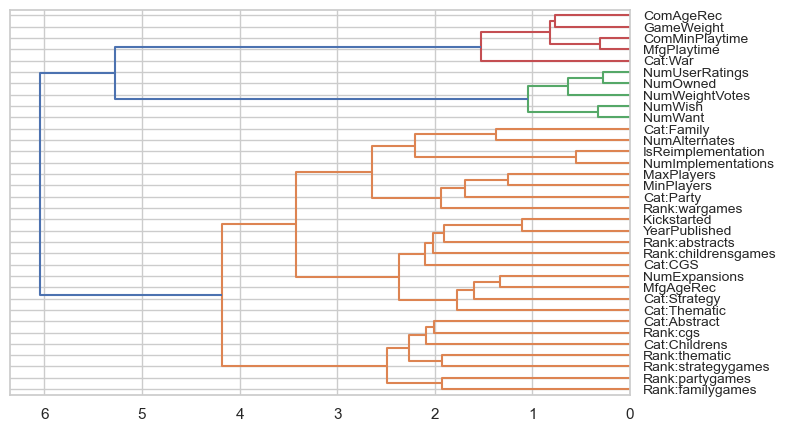

In [3]:
# Assicurati di avere scipy installato: pip install scipy
import scipy.cluster.hierarchy as sch

# --- Inserisci questo codice nella sezione CORRELAZIONE del tuo script ---

# 1. Calcola la matrice di correlazione
M_Cor = df_capped_num.corr(method="pearson")

# 2. Esegui il clustering gerarchico per trovare l'ordine ottimale
# Usiamo la distanza (1 - correlazione) per il clustering
distanze = sch.distance.pdist(M_Cor)
linkage = sch.linkage(distanze, method='ward')
dendrogramma = sch.dendrogram(linkage, labels=M_Cor.columns, orientation='left', leaf_font_size=10)

# 3. Ottieni l'ordine delle colonne dal dendrogramma
ordine_colonne = dendrogramma['ivl']

# 4. Riordina la matrice di correlazione
M_Cor_riordinata = M_Cor.loc[ordine_colonne, ordine_colonne]

# 5. Applica lo stile alla matrice RIORDINATA
# Questa riga produrrà la tabella colorata e ordinata
M_Cor_riordinata.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)



--- Top 20 coppie di variabili più correlate ---
       Variabile 1        Variabile 2  Correlaziones
          NumOwned     NumUserRatings       0.953744
           NumWant            NumWish       0.926294
       MfgPlaytime     ComMinPlaytime       0.892411
    NumWeightVotes     NumUserRatings       0.873279
          NumOwned     NumWeightVotes       0.824668
           NumWish     NumUserRatings       0.808236
          NumOwned            NumWish       0.796836
           NumWant     NumUserRatings       0.743331
          NumOwned            NumWant       0.733993
        GameWeight        MfgPlaytime       0.715554
           NumWant     NumWeightVotes       0.680845
NumImplementations IsReimplementation       0.679823
           NumWish     NumWeightVotes       0.679598
        GameWeight          ComAgeRec       0.670439
        GameWeight     ComMinPlaytime       0.660261
         ComAgeRec        MfgPlaytime       0.646497
         ComAgeRec     ComMinPlaytime       0.616

ValueError: Contour levels must be increasing

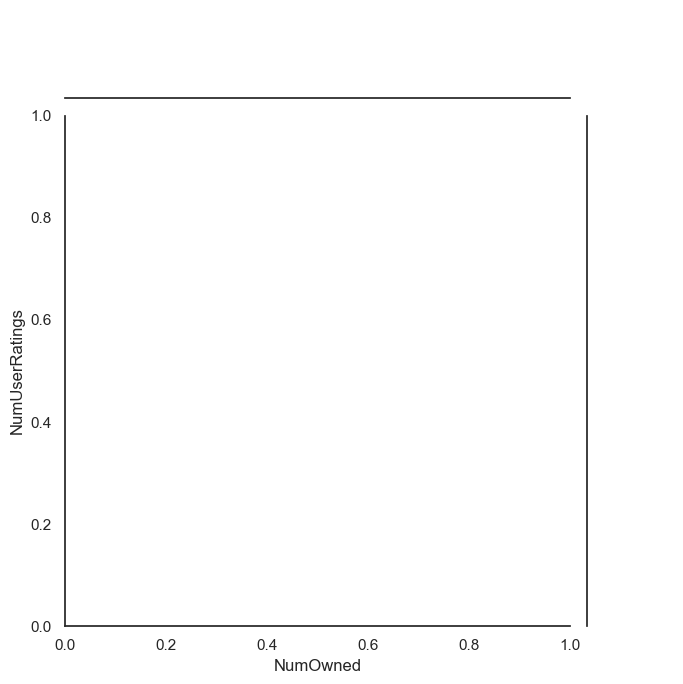

In [14]:
# -----------------------------------------------
# CORRELAZIONE

df_capped_num = df_capped.drop(["BGGId", "Name", "Description", "Family", "Rating"], axis=1)

# 1. Calcola la matrice di correlazione
M_Cor = df_capped_num.corr()

# 2. "Appiattisci" la matrice per ottenere una lista di coppie, rimuovendo duplicati e auto-correlazioni
corr_pairs = M_Cor.where(np.triu(np.ones(M_Cor.shape), k=1).astype(bool)).stack().reset_index()
corr_pairs.columns = ['Variabile 1', 'Variabile 2', 'Correlazione']

# 3. Ordina le coppie in base al valore assoluto della correlazione per trovare le più forti
corr_pairs['Correlaziones'] = corr_pairs['Correlazione'].abs()
sorted_corr = corr_pairs.sort_values(by='Correlazione', ascending=False).drop(columns='Correlazione')

# 4. Stampa le 20 coppie di variabili più correlate
print("\n--- Top 20 coppie di variabili più correlate ---")
print(sorted_corr.head(20).to_string(index=False))

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.impute import KNNImputer
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="white")

# Crea il jointplot con kind='kde'
# fill=True colora le aree di densità
g = sns.jointplot(
    data=df, 
    x='NumOwned', 
    y='NumUserRatings', 
    kind='kde',  # <-- Tipo di grafico: stima di densità
    fill=True,
    cmap="Blues", # Mappa di colori
    height=7
)

g.set_axis_labels('Numero Posseduto (NumOwned)', 'Altra Variabile', fontsize=12)
g.fig.suptitle('Grafico di Densità 2D (KDE) per Correlazione', y=1.02) # Titolo

plt.show()